In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
df = pd.read_csv(
    "price_drift_tracker_dataset.csv"
)

In [21]:
df.head()

,Product_ID,Product_Name,Category,Date,Platform,Previous_Price,Current_Price,Discount_Percentage,Rating,Price_Difference,Price_Change_Percentage
0,P001,Smartphone,Electronics,2026-01-13,Amazon,NaN,23780,6.6,3.9,NaN,NaN
1,P001,Smartphone,Electronics,2026-02-12,Amazon,23780.0,24000,11.9,3.9,220.0,0.93
2,P001,Smartphone,Electronics,2026-03-04,Amazon,24000.0,23190,5.8,3.9,-810.0,-3.38
3,P001,Smartphone,Electronics,2026-06-12,Amazon,23190.0,20000,25.3,3.9,-3190.0,-13.76
4,P001,Smartphone,Electronics,2026-01-21,Croma,NaN,24840,22.3,3.9,NaN,NaN


In [22]:
df.tail()

,Product_ID,Product_Name,Category,Date,Platform,Previous_Price,Current_Price,Discount_Percentage,Rating,Price_Difference,Price_Change_Percentage
995,P100,Fitness Tracker Pro,Sports & Fitness,2026-03-11,Croma,4880.0,4890,20.8,3.2,10.0,0.20
996,P100,Fitness Tracker Pro,Sports & Fitness,2026-04-02,Croma,4890.0,5120,7.0,3.2,230.0,4.70
997,P100,Fitness Tracker Pro,Sports & Fitness,2026-06-19,Croma,5120.0,5270,1.7,3.2,150.0,2.93
998,P100,Fitness Tracker Pro,Sports & Fitness,2026-01-19,Flipkart,NaN,4640,6.5,3.2,NaN,NaN
999,P100,Fitness Tracker Pro,Sports & Fitness,2026-06-11,Flipkart,4640.0,4560,10.4,3.2,-80.0,-1.72


In [23]:
df.shape

(1000, 11)

In [24]:
df.columns

Index(['Product_ID', 'Product_Name', 'Category', 'Date', 'Platform',
       'Previous_Price', 'Current_Price', 'Discount_Percentage', 'Rating',
       'Price_Difference', 'Price_Change_Percentage'],
      dtype='object')

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Product_ID               1000 non-null   object 
 1   Product_Name             1000 non-null   object 
 2   Category                 1000 non-null   object 
 3   Date                     1000 non-null   object 
 4   Platform                 1000 non-null   object 
 5   Previous_Price           700 non-null    float64
 6   Current_Price            1000 non-null   int64  
 7   Discount_Percentage      1000 non-null   float64
 8   Rating                   1000 non-null   float64
 9   Price_Difference         700 non-null    float64
 10  Price_Change_Percentage  700 non-null    float64
dtypes: float64(5), int64(1), object(5)
memory usage: 86.1+ KB


In [26]:
df.describe()

,Previous_Price,Current_Price,Discount_Percentage,Rating,Price_Difference,Price_Change_Percentage
count,700.000000,1000.000000,1000.000000,1000.000000,700.000000,700.000000
mean,9349.728571,9295.910000,12.164200,4.009200,11.000000,0.202486
std,16199.445170,16314.321109,7.772138,0.475859,923.279516,5.066155
min,180.000000,180.000000,0.000000,3.200000,-6490.000000,-17.330000
25%,967.500000,977.500000,6.275000,3.600000,-60.000000,-2.550000
50%,2915.000000,2930.000000,11.900000,4.000000,0.000000,0.000000
75%,7607.500000,7425.000000,17.700000,4.400000,80.000000,2.670000
max,101850.000000,105420.000000,39.600000,4.900000,9760.000000,21.190000


Check Missing Values

In [27]:
df.isnull().sum()

Product_ID                   0
Product_Name                 0
Category                     0
Date                         0
Platform                     0
Previous_Price             300
Current_Price                0
Discount_Percentage          0
Rating                       0
Price_Difference           300
Price_Change_Percentage    300
dtype: int64

In [28]:
(df.isnull().sum()/len(df))*100

Product_ID                  0.0
Product_Name                0.0
Category                    0.0
Date                        0.0
Platform                    0.0
Previous_Price             30.0
Current_Price               0.0
Discount_Percentage         0.0
Rating                      0.0
Price_Difference           30.0
Price_Change_Percentage    30.0
dtype: float64

Check Duplicate Records

In [29]:
df.duplicated().sum()

np.int64(0)

Convert Date Column

In [30]:
#currently Date → object  we need Date → datetime64
df['Date'] = pd.to_datetime(df['Date'])

In [31]:
df.info

<bound method DataFrame.info of     Product_ID         Product_Name          Category       Date  Platform  \
0         P001           Smartphone       Electronics 2026-01-13    Amazon   
1         P001           Smartphone       Electronics 2026-02-12    Amazon   
2         P001           Smartphone       Electronics 2026-03-04    Amazon   
3         P001           Smartphone       Electronics 2026-06-12    Amazon   
4         P001           Smartphone       Electronics 2026-01-21     Croma   
..         ...                  ...               ...        ...       ...   
995       P100  Fitness Tracker Pro  Sports & Fitness 2026-03-11     Croma   
996       P100  Fitness Tracker Pro  Sports & Fitness 2026-04-02     Croma   
997       P100  Fitness Tracker Pro  Sports & Fitness 2026-06-19     Croma   
998       P100  Fitness Tracker Pro  Sports & Fitness 2026-01-19  Flipkart   
999       P100  Fitness Tracker Pro  Sports & Fitness 2026-06-11  Flipkart   

     Previous_Price  Current_Pr

Check Unique Values

In [32]:
df['Category'].unique()

array(['Electronics', 'Home Appliances', 'Fashion',
       'Beauty & Personal Care', 'Sports & Fitness'], dtype=object)

In [33]:
df['Platform'].unique()

array(['Amazon', 'Croma', 'Flipkart'], dtype=object)

In [34]:
df['Product_ID'].nunique()

100

In [35]:
df['Product_Name'].nunique()

100

Check Price Values

In [36]:
df[['Previous_Price', 'Current_Price']].describe()

,Previous_Price,Current_Price
count,700.000000,1000.000000
mean,9349.728571,9295.910000
std,16199.445170,16314.321109
min,180.000000,180.000000
25%,967.500000,977.500000
50%,2915.000000,2930.000000
75%,7607.500000,7425.000000
max,101850.000000,105420.000000


In [37]:
(df['Current_Price'] <= 0).sum()

np.int64(0)

## Exploratory Data Analysis (EDA)

In [38]:
df.shape[0]

1000

In [39]:
df['Product_ID'].nunique()

100

In [40]:
df['Category'].nunique()

5

In [41]:
df['Platform'].nunique()

3

In [42]:
df['Category'].unique()

array(['Electronics', 'Home Appliances', 'Fashion',
       'Beauty & Personal Care', 'Sports & Fitness'], dtype=object)

Statistical Analysis

In [43]:
df['Current_Price'].mean()

np.float64(9295.91)

Highest product price

In [44]:
df['Current_Price'].max()

105420

Lowest product price

In [45]:
df['Current_Price'].min()

180

Median

In [46]:
df['Current_Price'].median()

2930.0

Complete statistical summary

In [47]:
df['Current_Price'].describe()

count      1000.000000
mean       9295.910000
std       16314.321109
min         180.000000
25%         977.500000
50%        2930.000000
75%        7425.000000
max      105420.000000
Name: Current_Price, dtype: float64

Category-Wise Price Analysis

In [48]:
category_price = df.groupby('Category')['Current_Price'].mean()

category_price

Category
Beauty & Personal Care     1063.959391
Electronics               21407.227723
Fashion                    2444.010152
Home Appliances           14178.317308
Sports & Fitness           6793.316327
Name: Current_Price, dtype: float64

Visualize category-wise prices

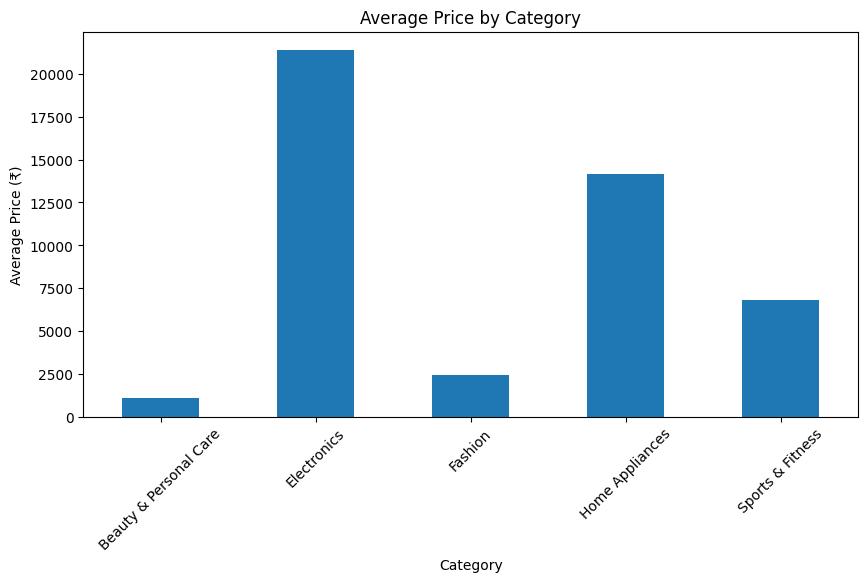

In [51]:
category_price.plot(
    kind='bar',
    figsize=(10,5),
    title='Average Price by Category'
)

plt.xlabel('Category')
plt.ylabel('Average Price (₹)')
plt.xticks(rotation=45)
plt.show()

Platform-Wise Price Analysis

In [52]:
platform_price = df.groupby('Platform')['Current_Price'].mean()

platform_price

Platform
Amazon      9464.839650
Croma       9648.218750
Flipkart    8789.436202
Name: Current_Price, dtype: float64

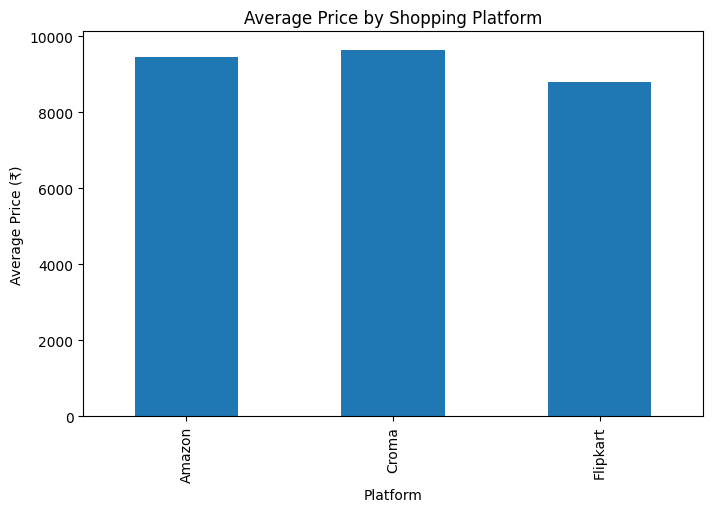

In [53]:
platform_price.plot(
    kind='bar',
    figsize=(8,5),
    title='Average Price by Shopping Platform'
)

plt.xlabel('Platform')
plt.ylabel('Average Price (₹)')
plt.show()

Price Drift Analysis

In [54]:
def price_status(value):

    if pd.isna(value):
        return 'No Previous Price'

    elif value > 0:
        return 'Price Increased'

    elif value < 0:
        return 'Price Decreased'

    else:
        return 'No Change'


df['Price_Status'] = df['Price_Difference'].apply(price_status)

Count price changes

In [55]:
df['Price_Status'].value_counts()

Price_Status
Price Increased      327
Price Decreased      319
No Previous Price    300
No Change             54
Name: count, dtype: int64

Visualize price changes

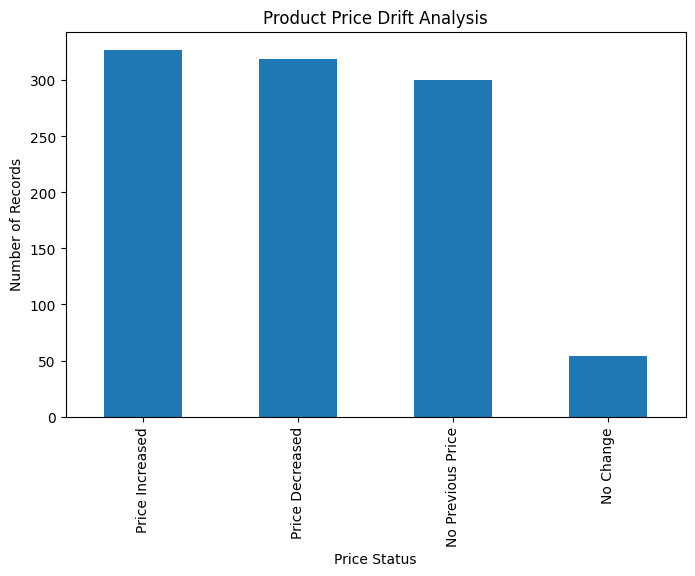

In [56]:
df['Price_Status'].value_counts().plot(
    kind='bar',
    figsize=(8,5),
    title='Product Price Drift Analysis'
)

plt.xlabel('Price Status')
plt.ylabel('Number of Records')
plt.show()

Top 10 Price-Increased Products

In [57]:
top_increased = df.sort_values(
    by='Price_Change_Percentage',
    ascending=False
)

top_increased[
    ['Product_Name', 'Category', 'Platform',
     'Price_Difference', 'Price_Change_Percentage']
].head(10)

,Product_Name,Category,Platform,Price_Difference,Price_Change_Percentage
590,Wallet,Fashion,Amazon,250.0,21.19
786,Makeup Kit,Beauty & Personal Care,Amazon,370.0,18.59
582,Jacket Pro,Fashion,Croma,210.0,18.26
367,Washing Machine Pro,Home Appliances,Croma,2160.0,17.16
104,Bluetooth Speaker,Electronics,Croma,1300.0,17.13
506,Sunglasses Pro,Fashion,Croma,510.0,16.09
594,Wallet,Fashion,Flipkart,210.0,15.91
289,Electric Kettle,Home Appliances,Amazon,320.0,15.02
939,Treadmill Pro,Sports & Fitness,Flipkart,9760.0,14.77
292,Electric Kettle,Home Appliances,Croma,320.0,14.61


Top 10 Price-Decreased Products

In [58]:
top_decreased = df.sort_values(
    by='Price_Change_Percentage',
    ascending=True
)

top_decreased[
    ['Product_Name', 'Category', 'Platform',
     'Price_Difference', 'Price_Change_Percentage']
].head(10)

,Product_Name,Category,Platform,Price_Difference,Price_Change_Percentage
46,Tablet,Electronics,Croma,-6490.0,-17.33
714,Hair Dryer,Beauty & Personal Care,Flipkart,-260.0,-16.15
333,Refrigerator,Home Appliances,Croma,-4190.0,-15.31
681,Shampoo Pro,Beauty & Personal Care,Amazon,-130.0,-14.94
201,Keyboard Pro,Electronics,Flipkart,-100.0,-14.49
3,Smartphone,Electronics,Amazon,-3190.0,-13.76
90,Wireless Earbuds Pro,Electronics,Amazon,-1140.0,-12.97
610,Face Wash,Beauty & Personal Care,Amazon,-70.0,-12.96
945,Gym Gloves,Sports & Fitness,Croma,-110.0,-12.22
542,T-Shirt Pro,Fashion,Croma,-120.0,-12.12


Monthly Price Trend Analysis

In [59]:
df['Month'] = df['Date'].dt.month_name()

In [60]:
monthly_price = df.groupby('Month')['Current_Price'].mean()

monthly_price

Month
April       10397.876106
February     9657.419355
January      9144.666667
June         9170.333333
March        9425.463918
May          8392.164948
Name: Current_Price, dtype: float64

In [61]:
monthly_price = (
    df.set_index('Date')['Current_Price']
    .resample('MS')
    .mean()
)

monthly_price

Date
2026-01-01     9144.666667
2026-02-01     9657.419355
2026-03-01     9425.463918
2026-04-01    10397.876106
2026-05-01     8392.164948
2026-06-01     9170.333333
Freq: MS, Name: Current_Price, dtype: float64

Monthly Price Trend Visualization

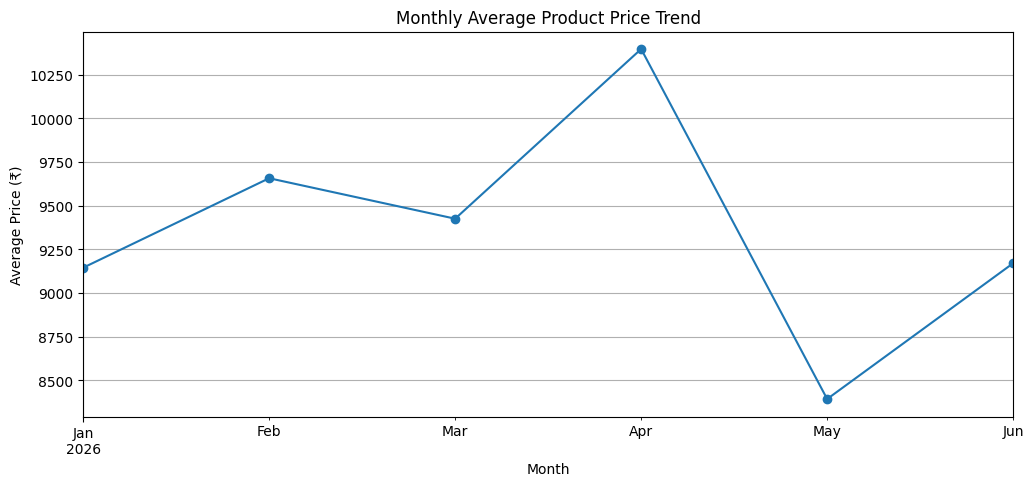

In [62]:
monthly_price.plot(
    kind='line',
    figsize=(12,5),
    marker='o',
    title='Monthly Average Product Price Trend'
)

plt.xlabel('Month')
plt.ylabel('Average Price (₹)')
plt.grid(True)
plt.show()

## SQL Analysis

In [63]:
import sqlite3
import pandas as pd

In [64]:
conn = sqlite3.connect('price_drift_tracker.db')

In [65]:
df.to_sql(
    'price_data',
    conn,
    if_exists='replace',
    index=False
)

1000

In [66]:
query = """
SELECT *
FROM price_data
LIMIT 5;
"""

pd.read_sql(query, conn)

,Product_ID,Product_Name,Category,Date,Platform,Previous_Price,Current_Price,Discount_Percentage,Rating,Price_Difference,Price_Change_Percentage,Price_Status,Month
0,P001,Smartphone,Electronics,2026-01-13 00:00:00,Amazon,NaN,23780,6.6,3.9,NaN,NaN,No Previous Price,January
1,P001,Smartphone,Electronics,2026-02-12 00:00:00,Amazon,23780.0,24000,11.9,3.9,220.0,0.93,Price Increased,February
2,P001,Smartphone,Electronics,2026-03-04 00:00:00,Amazon,24000.0,23190,5.8,3.9,-810.0,-3.38,Price Decreased,March
3,P001,Smartphone,Electronics,2026-06-12 00:00:00,Amazon,23190.0,20000,25.3,3.9,-3190.0,-13.76,Price Decreased,June
4,P001,Smartphone,Electronics,2026-01-21 00:00:00,Croma,NaN,24840,22.3,3.9,NaN,NaN,No Previous Price,January


Total Number of Products

In [70]:
query = """
SELECT COUNT(DISTINCT Product_ID)
FROM price_data;
"""

result = pd.read_sql(query, conn)

result

,COUNT(DISTINCT Product_ID)
0,100


In [71]:
query = """
SELECT ROUND(AVG(Current_Price), 2)
FROM price_data;
"""

result = pd.read_sql(query, conn)

result

,"ROUND(AVG(Current_Price), 2)"
0,9295.91


In [72]:
query = """
SELECT
    Category,
    ROUND(AVG(Current_Price), 2) AS Average_Price
FROM price_data
GROUP BY Category
ORDER BY Average_Price DESC;
"""

result = pd.read_sql(query, conn)

result

,Category,Average_Price
0,Electronics,21407.23
1,Home Appliances,14178.32
2,Sports & Fitness,6793.32
3,Fashion,2444.01
4,Beauty & Personal Care,1063.96


In [73]:
query = """
SELECT
    Platform,
    ROUND(AVG(Current_Price), 2) AS Average_Price
FROM price_data
GROUP BY Platform
ORDER BY Average_Price ASC;
"""

result = pd.read_sql(query, conn)

result

,Platform,Average_Price
0,Flipkart,8789.44
1,Amazon,9464.84
2,Croma,9648.22


In [77]:
query = """
SELECT
    Product_Name,
    Category,
    Platform,
    Price_Difference,
    Price_Change_Percentage
FROM price_data
WHERE Price_Change_Percentage IS NOT NULL
ORDER BY Price_Change_Percentage DESC
LIMIT 10;
"""

result = pd.read_sql(query, conn)

result

,Product_Name,Category,Platform,Price_Difference,Price_Change_Percentage
0,Wallet,Fashion,Amazon,250.0,21.19
1,Makeup Kit,Beauty & Personal Care,Amazon,370.0,18.59
2,Jacket Pro,Fashion,Croma,210.0,18.26
3,Washing Machine Pro,Home Appliances,Croma,2160.0,17.16
4,Bluetooth Speaker,Electronics,Croma,1300.0,17.13
5,Sunglasses Pro,Fashion,Croma,510.0,16.09
6,Wallet,Fashion,Flipkart,210.0,15.91
7,Electric Kettle,Home Appliances,Amazon,320.0,15.02
8,Treadmill Pro,Sports & Fitness,Flipkart,9760.0,14.77
9,Electric Kettle,Home Appliances,Croma,320.0,14.61


In [78]:
query = """
SELECT
    Product_Name,
    Category,
    Platform,
    Price_Difference,
    Price_Change_Percentage
FROM price_data
WHERE Price_Change_Percentage IS NOT NULL
ORDER BY Price_Change_Percentage ASC
LIMIT 10;
"""

result = pd.read_sql(query, conn)

result

,Product_Name,Category,Platform,Price_Difference,Price_Change_Percentage
0,Tablet,Electronics,Croma,-6490.0,-17.33
1,Hair Dryer,Beauty & Personal Care,Flipkart,-260.0,-16.15
2,Refrigerator,Home Appliances,Croma,-4190.0,-15.31
3,Shampoo Pro,Beauty & Personal Care,Amazon,-130.0,-14.94
4,Keyboard Pro,Electronics,Flipkart,-100.0,-14.49
5,Smartphone,Electronics,Amazon,-3190.0,-13.76
6,Wireless Earbuds Pro,Electronics,Amazon,-1140.0,-12.97
7,Face Wash,Beauty & Personal Care,Amazon,-70.0,-12.96
8,Gym Gloves,Sports & Fitness,Croma,-110.0,-12.22
9,T-Shirt Pro,Fashion,Croma,-120.0,-12.12


SQL Analysis of your Price Drift Tracker

In [79]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('price_drift_tracker.db')

df.to_sql('price_data', conn, if_exists='replace', index=False)

1000

In [80]:
query = """
SELECT *
FROM price_data
LIMIT 5;
"""

pd.read_sql_query(query, conn)

,Product_ID,Product_Name,Category,Date,Platform,Previous_Price,Current_Price,Discount_Percentage,Rating,Price_Difference,Price_Change_Percentage,Price_Status,Month
0,P001,Smartphone,Electronics,2026-01-13 00:00:00,Amazon,NaN,23780,6.6,3.9,NaN,NaN,No Previous Price,January
1,P001,Smartphone,Electronics,2026-02-12 00:00:00,Amazon,23780.0,24000,11.9,3.9,220.0,0.93,Price Increased,February
2,P001,Smartphone,Electronics,2026-03-04 00:00:00,Amazon,24000.0,23190,5.8,3.9,-810.0,-3.38,Price Decreased,March
3,P001,Smartphone,Electronics,2026-06-12 00:00:00,Amazon,23190.0,20000,25.3,3.9,-3190.0,-13.76,Price Decreased,June
4,P001,Smartphone,Electronics,2026-01-21 00:00:00,Croma,NaN,24840,22.3,3.9,NaN,NaN,No Previous Price,January


Advanced SQL

GROUP BY

In [81]:
query = """
SELECT Category,
       COUNT(DISTINCT Product_ID) AS Total_Products
FROM price_data
GROUP BY Category;
"""

pd.read_sql_query(query, conn)

,Category,Total_Products
0,Beauty & Personal Care,20
1,Electronics,20
2,Fashion,20
3,Home Appliances,20
4,Sports & Fitness,20


HAVING

In [82]:
query = """
SELECT Category,
       COUNT(DISTINCT Product_ID) AS Total_Products
FROM price_data
GROUP BY Category
HAVING COUNT(DISTINCT Product_ID) > 15;
"""

pd.read_sql_query(query, conn)

,Category,Total_Products
0,Beauty & Personal Care,20
1,Electronics,20
2,Fashion,20
3,Home Appliances,20
4,Sports & Fitness,20


CASE WHEN

In [83]:
query = """
SELECT Product_Name,
       Platform,
       Price_Difference,
       CASE
           WHEN Price_Difference > 0 THEN 'Price Increased'
           WHEN Price_Difference < 0 THEN 'Price Decreased'
           WHEN Price_Difference = 0 THEN 'No Change'
           ELSE 'No Previous Price'
       END AS Price_Status
FROM price_data
LIMIT 20;
"""

result = pd.read_sql_query(query, conn)
result

,Product_Name,Platform,Price_Difference,Price_Status
0,Smartphone,Amazon,NaN,No Previous Price
1,Smartphone,Amazon,220.0,Price Increased
2,Smartphone,Amazon,-810.0,Price Decreased
3,Smartphone,Amazon,-3190.0,Price Decreased
4,Smartphone,Croma,NaN,No Previous Price
5,Smartphone,Croma,1540.0,Price Increased
6,Smartphone,Croma,-500.0,Price Decreased
7,Smartphone,Flipkart,NaN,No Previous Price
8,Smartphone,Flipkart,1790.0,Price Increased
9,Smartphone,Flipkart,110.0,Price Increased


Subqueries

In [84]:
query = """
SELECT Product_Name,
       Category,
       Platform,
       Current_Price
FROM price_data
WHERE Current_Price > (
    SELECT AVG(Current_Price)
    FROM price_data
)
ORDER BY Current_Price DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
result

,Product_Name,Category,Platform,Current_Price
0,Laptop Pro,Electronics,Amazon,105420
1,Laptop Pro,Electronics,Amazon,101850
2,Laptop Pro,Electronics,Croma,97460
3,Laptop Pro,Electronics,Croma,95700
4,Laptop Pro,Electronics,Flipkart,95250
5,Laptop Pro,Electronics,Amazon,94700
6,Laptop Pro,Electronics,Croma,94380
7,Laptop Pro,Electronics,Croma,94340
8,Laptop Pro,Electronics,Flipkart,93110
9,Smartphone Pro,Electronics,Croma,80550


RANK()

In [85]:
query = """
SELECT Product_Name,
       Category,
       Platform,
       Current_Price,
       RANK() OVER (
           PARTITION BY Category
           ORDER BY Current_Price DESC
       ) AS Price_Rank
FROM price_data
LIMIT 20;
"""

result = pd.read_sql_query(query, conn)
result

,Product_Name,Category,Platform,Current_Price,Price_Rank
0,Hair Dryer Pro,Beauty & Personal Care,Croma,3170,1
1,Hair Dryer Pro,Beauty & Personal Care,Croma,3150,2
2,Hair Dryer Pro,Beauty & Personal Care,Flipkart,3120,3
3,Hair Dryer Pro,Beauty & Personal Care,Flipkart,3070,4
4,Hair Dryer Pro,Beauty & Personal Care,Amazon,3060,5
5,Hair Dryer Pro,Beauty & Personal Care,Amazon,3050,6
6,Hair Dryer Pro,Beauty & Personal Care,Flipkart,3020,7
7,Hair Dryer Pro,Beauty & Personal Care,Flipkart,2960,8
8,Hair Dryer Pro,Beauty & Personal Care,Flipkart,2960,8
9,Makeup Kit Pro,Beauty & Personal Care,Flipkart,2950,10


In [86]:
query = """
SELECT Product_Name,
       Category,
       Platform,
       Current_Price,

       RANK() OVER (
           PARTITION BY Category
           ORDER BY Current_Price DESC
       ) AS Price_Rank,

       DENSE_RANK() OVER (
           PARTITION BY Category
           ORDER BY Current_Price DESC
       ) AS Dense_Price_Rank,

       ROW_NUMBER() OVER (
           PARTITION BY Category
           ORDER BY Current_Price DESC
       ) AS Row_Num

FROM price_data
LIMIT 20;
"""

result = pd.read_sql_query(query, conn)
result

,Product_Name,Category,Platform,Current_Price,Price_Rank,Dense_Price_Rank,Row_Num
0,Hair Dryer Pro,Beauty & Personal Care,Croma,3170,1,1,1
1,Hair Dryer Pro,Beauty & Personal Care,Croma,3150,2,2,2
2,Hair Dryer Pro,Beauty & Personal Care,Flipkart,3120,3,3,3
3,Hair Dryer Pro,Beauty & Personal Care,Flipkart,3070,4,4,4
4,Hair Dryer Pro,Beauty & Personal Care,Amazon,3060,5,5,5
5,Hair Dryer Pro,Beauty & Personal Care,Amazon,3050,6,6,6
6,Hair Dryer Pro,Beauty & Personal Care,Flipkart,3020,7,7,7
7,Hair Dryer Pro,Beauty & Personal Care,Flipkart,2960,8,8,8
8,Hair Dryer Pro,Beauty & Personal Care,Flipkart,2960,8,8,9
9,Makeup Kit Pro,Beauty & Personal Care,Flipkart,2950,10,9,10


In [87]:
query = """
WITH Ranked_Products AS (
    SELECT
        Product_Name,
        Category,
        Platform,
        Current_Price,

        DENSE_RANK() OVER (
            PARTITION BY Platform
            ORDER BY Current_Price DESC
        ) AS Price_Rank

    FROM price_data
)

SELECT *
FROM Ranked_Products
WHERE Price_Rank <= 3
ORDER BY Platform, Price_Rank;
"""

result = pd.read_sql_query(query, conn)
result

,Product_Name,Category,Platform,Current_Price,Price_Rank
0,Laptop Pro,Electronics,Amazon,105420,1
1,Laptop Pro,Electronics,Amazon,101850,2
2,Laptop Pro,Electronics,Amazon,94700,3
3,Laptop Pro,Electronics,Croma,97460,1
4,Laptop Pro,Electronics,Croma,95700,2
5,Laptop Pro,Electronics,Croma,94380,3
6,Laptop Pro,Electronics,Flipkart,95250,1
7,Laptop Pro,Electronics,Flipkart,93110,2
8,Treadmill Pro,Sports & Fitness,Flipkart,75830,3


cheapest platform for each product

In [88]:
query = """
WITH Cheapest_Platform AS (
    SELECT
        Product_ID,
        Product_Name,
        Category,
        Platform,
        Current_Price,

        ROW_NUMBER() OVER (
            PARTITION BY Product_ID
            ORDER BY Current_Price ASC, Platform ASC
        ) AS Price_Rank

    FROM price_data
)

SELECT
    Product_Name,
    Category,
    Platform,
    Current_Price
FROM Cheapest_Platform
WHERE Price_Rank = 1
ORDER BY Current_Price ASC;
"""

result = pd.read_sql_query(query, conn)
result

,Product_Name,Category,Platform,Current_Price
0,Face Wash Pro,Beauty & Personal Care,Amazon,180
1,Resistance Bands Pro,Sports & Fitness,Amazon,210
2,Body Lotion Pro,Beauty & Personal Care,Amazon,230
3,Moisturizer,Beauty & Personal Care,Amazon,310
4,Shampoo,Beauty & Personal Care,Flipkart,340
...,...,...,...,...
95,Washing Machine,Home Appliances,Flipkart,44090
96,Refrigerator Pro,Home Appliances,Flipkart,46580
97,Treadmill Pro,Sports & Fitness,Amazon,61610
98,Smartphone Pro,Electronics,Amazon,68100


latest price for each product-platform combination

In [89]:
query = """
WITH Latest_Prices AS (
    SELECT
        Product_ID,
        Product_Name,
        Category,
        Platform,
        Date,
        Current_Price,

        ROW_NUMBER() OVER (
            PARTITION BY Product_ID, Platform
            ORDER BY Date DESC
        ) AS Row_Num

    FROM price_data
)

SELECT
    Product_ID,
    Product_Name,
    Category,
    Platform,
    Date,
    Current_Price

FROM Latest_Prices
WHERE Row_Num = 1
ORDER BY Product_Name, Platform;
"""

result = pd.read_sql_query(query, conn)
result

,Product_ID,Product_Name,Category,Platform,Date,Current_Price
0,P023,Air Fryer,Home Appliances,Amazon,2026-06-23 00:00:00,10650
1,P023,Air Fryer,Home Appliances,Croma,2026-06-23 00:00:00,11020
2,P023,Air Fryer,Home Appliances,Flipkart,2026-06-05 00:00:00,10390
3,P024,Air Fryer Pro,Home Appliances,Amazon,2026-06-07 00:00:00,6490
4,P024,Air Fryer Pro,Home Appliances,Croma,2026-06-07 00:00:00,7260
...,...,...,...,...,...,...
295,P081,Yoga Mat,Sports & Fitness,Croma,2026-06-08 00:00:00,530
296,P081,Yoga Mat,Sports & Fitness,Flipkart,2026-06-25 00:00:00,530
297,P082,Yoga Mat Pro,Sports & Fitness,Amazon,2026-06-17 00:00:00,1200
298,P082,Yoga Mat Pro,Sports & Fitness,Croma,2026-06-02 00:00:00,1280


platform comparison table

In [90]:
query = """
WITH Latest_Prices AS (
    SELECT
        Product_ID,
        Product_Name,
        Category,
        Platform,
        Date,
        Current_Price,

        ROW_NUMBER() OVER (
            PARTITION BY Product_ID, Platform
            ORDER BY Date DESC
        ) AS Row_Num

    FROM price_data
)

SELECT
    Product_ID,
    Product_Name,
    Category,

    MAX(CASE WHEN Platform = 'Amazon'
        THEN Current_Price END) AS Amazon_Price,

    MAX(CASE WHEN Platform = 'Flipkart'
        THEN Current_Price END) AS Flipkart_Price,

    MAX(CASE WHEN Platform = 'Croma'
        THEN Current_Price END) AS Croma_Price

FROM Latest_Prices
WHERE Row_Num = 1
GROUP BY Product_ID, Product_Name, Category
ORDER BY Product_ID;
"""

comparison = pd.read_sql_query(query, conn)
comparison

,Product_ID,Product_Name,Category,Amazon_Price,Flipkart_Price,Croma_Price
0,P001,Smartphone,Electronics,20000,24510,25880
1,P002,Smartphone Pro,Electronics,68100,69740,80550
2,P003,Laptop,Electronics,37760,45450,39850
3,P004,Laptop Pro,Electronics,105420,95250,94380
4,P005,Tablet,Electronics,36780,35730,30950
...,...,...,...,...,...,...
95,P096,Gym Gloves Pro,Sports & Fitness,660,750,710
96,P097,Skipping Rope,Sports & Fitness,470,380,440
97,P098,Skipping Rope Pro,Sports & Fitness,370,380,460
98,P099,Fitness Tracker,Sports & Fitness,5040,4550,5570


cheapest platform for every product

In [91]:
price_columns = ['Amazon_Price', 'Flipkart_Price', 'Croma_Price']

comparison['Cheapest_Platform'] = (
    comparison[price_columns]
    .idxmin(axis=1)
    .str.replace('_Price', '')
)

comparison['Lowest_Price'] = comparison[price_columns].min(axis=1)

comparison['Highest_Price'] = comparison[price_columns].max(axis=1)

comparison['Price_Difference'] = (
    comparison['Highest_Price'] - comparison['Lowest_Price']
)

comparison.head(10)

,Product_ID,Product_Name,Category,Amazon_Price,Flipkart_Price,Croma_Price,Cheapest_Platform,Lowest_Price,Highest_Price,Price_Difference
0,P001,Smartphone,Electronics,20000,24510,25880,Amazon,20000,25880,5880
1,P002,Smartphone Pro,Electronics,68100,69740,80550,Amazon,68100,80550,12450
2,P003,Laptop,Electronics,37760,45450,39850,Amazon,37760,45450,7690
3,P004,Laptop Pro,Electronics,105420,95250,94380,Croma,94380,105420,11040
4,P005,Tablet,Electronics,36780,35730,30950,Croma,30950,36780,5830
5,P006,Tablet Pro,Electronics,35910,35710,34730,Croma,34730,35910,1180
6,P007,Smartwatch,Electronics,16680,15040,17850,Flipkart,15040,17850,2810
7,P008,Smartwatch Pro,Electronics,10580,10040,9650,Croma,9650,10580,930
8,P009,Wireless Earbuds,Electronics,9850,9500,9420,Croma,9420,9850,430
9,P010,Wireless Earbuds Pro,Electronics,7650,7970,8840,Amazon,7650,8840,1190


Which platform offers the lowest prices most often?

In [92]:
comparison['Cheapest_Platform'].value_counts()

Cheapest_Platform
Flipkart    42
Amazon      39
Croma       19
Name: count, dtype: int64

potential customer savings

In [93]:
total_savings = comparison['Price_Difference'].sum()

average_savings = comparison['Price_Difference'].mean()

print("Total Potential Savings: ₹", round(total_savings, 2))
print("Average Price Difference: ₹", round(average_savings, 2))

Total Potential Savings: ₹ 133300
Average Price Difference: ₹ 1333.0


In [94]:
comparison.to_csv('price_comparison.csv', index=False)

comparison.to_excel('price_comparison.xlsx', index=False)

print("Files exported successfully!")

Files exported successfully!
